Epoch 1/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 367us/step - loss: 0.8136 - mae: 0.6072 - val_loss: 0.6356 - val_mae: 0.5531
Epoch 2/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 0s 307us/step - loss: 0.5841 - mae: 0.5212 - val_loss: 0.5218 - val_mae: 0.4983
Epoch 3/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 0s 310us/step - loss: 0.5235 - mae: 0.4895 - val_loss: 0.4914 - val_mae: 0.4795
Epoch 4/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 0s 309us/step - loss: 0.4998 - mae: 0.4756 - val_loss: 0.4733 - val_mae: 0.4673
Epoch 5/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 0s 308us/step - loss: 0.4820 - mae: 0.4648 - val_loss: 0.4581 - val_mae: 0.4579
Epoch 6/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 0s 306us/step - loss: 0.4665 - mae: 0.4560 - val_loss: 0.4448 - val_mae: 0.4488
Epoch 7/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 0s 307us/step - loss: 0.4546 - mae: 0.4467 - val_loss: 0.4373 - val_mae: 0.4438
Epoch 8/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 0s 308us/step - loss: 0.4471 - mae: 0.4408 - val_loss: 0.4307 - val_mae: 0.4365
Epoch 9/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 

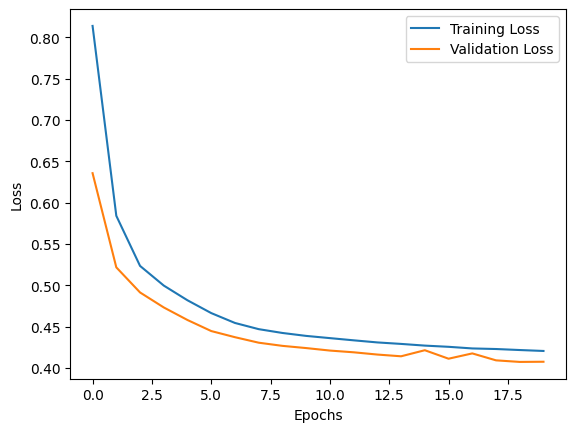

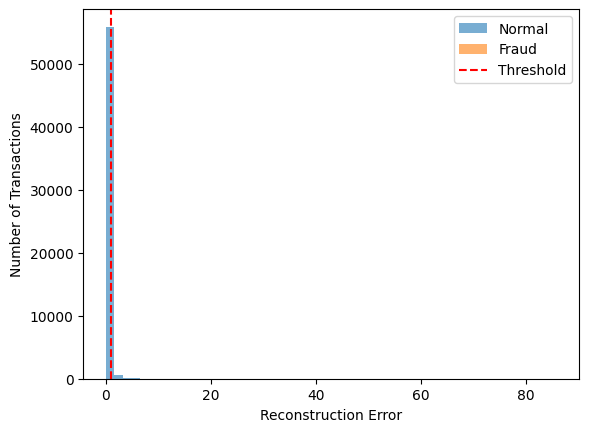

In [1]:
# 1. Import libraries
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix

# 2. Load and preprocess data
data = pd.read_csv("creditcard.csv")

X = data.drop("Class", axis=1)
y = data["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Train only on normal transactions
X_train_normal = X_train[y_train == 0]

scaler = StandardScaler()
X_train_normal = scaler.fit_transform(X_train_normal)
X_test = scaler.transform(X_test)

# 3. Build Autoencoder
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(30,)),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(8, activation="relu"),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(30, activation="linear")
])

# 4. Compile model
model.compile(optimizer="adam", loss="mse", metrics=["mae"])

# 5. Train autoencoder on normal transactions only
history = model.fit(
    X_train_normal, X_train_normal,
    epochs=20, batch_size=256,
    validation_split=0.1
)

# 6. Calculate reconstruction errors
predictions = model.predict(X_test)
errors = np.mean(np.square(X_test - predictions), axis=1)

# Set fraud detection threshold
train_predictions = model.predict(X_train_normal)
train_errors = np.mean(np.square(X_train_normal - train_predictions), axis=1)

threshold = np.percentile(train_errors, 95)
print("Threshold:", threshold)

# 7. Detect fraud
y_pred = (errors > threshold).astype(int)

# 8. Evaluate model
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("Classification Report:")
print(classification_report(y_test, y_pred))

# 9. Visualize loss
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

# Visualize reconstruction errors
plt.hist(errors[y_test == 0], bins=50, alpha=0.6, label="Normal")
plt.hist(errors[y_test == 1], bins=50, alpha=0.6, label="Fraud")
plt.axvline(threshold, color="red", linestyle="--", label="Threshold")
plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Transactions")
plt.legend()
plt.show()